# Refinamiento de velocidad normalizado por geometría

**Pregunta:** ¿El modelo residual aprendido reduce tanto el error de velocidad como el error de tiempo de viaje propagado de forma independiente en geologías y geometrías de adquisición no vistas?

**Ejercicio de método propuesto** · Prerrequisitos: tomografía de primeras llegadas, análisis dimensional, particiones agrupadas y errores pareados. **Tiempo:** 35–45 minutos.

Este notebook aplica el checkpoint congelado, entrenado en GPU, a encuestas sintéticas retenidas y deterministas. Ejecuta el modelo y una inversión de rayos regularizada, seleccionada en validación, sobre las mismas llegadas ruidosas. No reajusta con datos retenidos ni afirma desempeño de campo.

## Objetivos

- Derivar las unidades de la característica residual desde la ecuación de rayos rectos.
- Reconstruir cohortes declaradas sin solapamiento e inspeccionar su geometría.
- Aplicar el modelo guardado y la inversión regularizada a las mismas observaciones.
- Comparar errores de velocidad y tiempo independiente, e interpretar un resultado negativo.

## Preparación

Instala los pins analíticos y PyTorch CPU desde el índice oficial:

```bash
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8 torch==2.14.0 --extra-index-url https://download.pytorch.org/whl/cpu
```

Ejecuta `scripts/setup.ps1 -Notebooks` (o `scripts/setup.sh --notebooks`) para el entorno reproducible. La inferencia usa CPU. Para reproducir el entrenamiento CUDA de 40 épocas, instala además `scripts/setup.ps1 -Gpu` y ejecuta `python data-pipeline/velocity_physics_refinement.py --output <directorio-nuevo> --device cuda`.

Registra las versiones de los paquetes de análisis antes de abrir artefactos del experimento.

In [1]:
# Registra los paquetes e importa el pipeline del producto.
from importlib.metadata import version
import hashlib
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

root = next((path for path in (Path.cwd(), *Path.cwd().parents) if (path / "data-pipeline").is_dir()), None)
assert root is not None, "Ejecuta desde el árbol del repositorio"
sys.path.insert(0, str(root / "data-pipeline"))
import velocity_physics_refinement as experiment
import velocity_validation as inverse

print({name: version(name) for name in ("numpy", "scipy", "matplotlib", "torch")})

{'numpy': '2.2.6', 'scipy': '1.15.2', 'matplotlib': '3.10.8', 'torch': '2.14.0+cpu'}


## Datos

El pipeline genera encuestas sintéticas con familias de velocidad y semillas fijas; no descarga datos de terceros. La cohorte de cambio conjunto contiene 160 realizaciones nuevas de fallas y domos salinos con adquisición C. Las particiones usan semillas disjuntas y quedan registradas en el recibo. OpenFWI se cita como referencia pública de benchmark, pero sus datos no se cargan ni redistribuyen.

Se usa el checkpoint de `models/experimental/m12-physics-cuda-20261004/`. La siguiente celda verifica sus hashes, los manifiestos congelados y regenera las entradas retenidas.

Valida hashes del checkpoint y los manifiestos antes de regenerar las encuestas.

In [2]:
# Comprueba hashes y recrea los grupos sintéticos.
receipt_dir = root / "models/experimental/m12-physics-cuda-20261004"
receipt = json.loads((receipt_dir / "receipt.json").read_text(encoding="utf-8"))
checkpoint_path = receipt_dir / receipt["checkpoint"]
assert hashlib.sha256(checkpoint_path.read_bytes()).hexdigest() == receipt["checkpoint_sha256"]
source_hash = inverse.sha256_bytes(Path(experiment.__file__).read_bytes())
assert receipt["code_sha256"] in {source_hash, experiment.LEGACY_V2_TRAINING_SOURCE_SHA256}
assert inverse.sha256_bytes(Path(inverse.__file__).read_bytes()) == receipt["operator_code_sha256"]

ops = inverse.operators()
validation = experiment.make_cohort("validation", ops)
test_names = ("id_test", "family_only", "acquisition_only", "joint_ood")
cohorts = {name: experiment.make_cohort(name, ops) for name in test_names}
for name, cohort in (("validation", validation), *cohorts.items()):
    assert cohort["records"] == receipt["split_manifests"][name]
    assert cohort["manifest_sha256"] == receipt["split_hashes"][name]
print({name: len(cohort["records"]) for name, cohort in cohorts.items()})

{'id_test': 160, 'family_only': 80, 'acquisition_only': 80, 'joint_ood': 160}


## Método

Para el rayo `r`, la ecuación discretizada de rayos rectos es `t_r = Σ_j A_rj s_j + ε_r`, con longitudes `A_rj` en metros y lentitud `s_j = 1/v_j` en segundos por metro. El modelo de referencia es `s₀`; el residuo es `r_t = t_obs − A s₀` en segundos. Una característica física de primer orden es

`δs_r = r_t,r / L_r`, con `L_r = Σ_j A_rj` (s/m),

`h_j = Σ_r A_rj δs_r / c_j`, con `c_j = Σ_r A_rj` (s/m),

`x_j = −h_j v₀,j² / 400`, característica adimensional del ajuste de velocidad. El segundo canal registra cobertura de rayos normalizada. Las celdas sin cobertura reciben característica cero y permanecen explícitamente sin soporte.

La CNN residual queda limitada a 1.400–4.000 m/s y se inicializa para reproducir el modelo de referencia. El entrenamiento usa 800 realizaciones y 160 de validación; la validación selecciona época y regularización clásica. Las pruebas intactas contienen 160 casos ID, 80 con cambio de familia, 80 con cambio de adquisición y 160 con cambio conjunto. Ambos métodos reciben las mismas llegadas ruidosas por caso. El oráculo independiente propaga cada modelo.

Calcula la característica dimensional para una encuesta retenida y observa su cobertura.

In [3]:
# Calcula la característica normalizada de una realización retenida.
joint = cohorts["joint_ood"]
feature = experiment.input_features(joint["observed"][0], ops["C"]["cell"])
print({"shape": feature.shape, "unsupported_cells": int(np.count_nonzero(feature[1] == 0)),
       "coverage_max": float(feature[1].max())})

{'shape': (2, 16, 16), 'unsupported_cells': 5, 'coverage_max': 1.0}


## Comparación

La referencia es la inversión regularizada de rayos rectos; su peso se selecciona con validación separada. Ambos métodos reciben los mismos picks ruidosos. El error de velocidad se mide frente a la verdad sintética y el error de tiempo se recalcula con cuadratura bilineal independiente.

Göppel, Frikel y Haltmeier formulan redes de espacio nulo próximas a los datos para tomografía de vista limitada. Esta CNN residual no reproduce esa arquitectura. OpenFWI es un benchmark de forma de onda completa, no la fuente de estas primeras llegadas.

Selecciona la regularización usando solo validación; luego ejecuta ambos métodos en cohortes retenidas.

In [4]:
# Selecciona el parámetro en validación y puntúa cada método en las pruebas.
selected_lambda, candidates = inverse.select_classical(validation, ops)
experiment.verify_classical_selection(receipt["classical"], selected_lambda, candidates)
model = experiment.load_checkpoint(checkpoint_path, receipt["checkpoint_sha256"], device="cpu")
scores = {}
for name, cohort in cohorts.items():
    learned = inverse._predict(model, cohort, "cpu")
    reference = inverse.classical_predict(cohort, ops, selected_lambda)
    scores[name] = inverse.score(cohort, learned, reference, ops, receipt["forward_threshold_ms"])
print({name: (round(value["learned_to_classical_velocity_ratio"], 4),
              round(value["learned_to_classical_oracle_ratio"], 4))
       for name, value in scores.items()})

{'id_test': (2.9955, 4.4169), 'family_only': (2.1719, 5.562), 'acquisition_only': (3.0286, 4.7713), 'joint_ood': (2.1875, 5.4173)}


## Evidencia

El criterio exige que ambas razones de error en cambio conjunto sean menores que 1,0. La validación seleccionó el modelo; las cohortes de prueba no se usan para reajustar. Cada punto del siguiente gráfico representa una encuesta pareada.

Compara ambas razones de error físico entre selección y prueba; la línea de referencia marca desempeño equivalente.

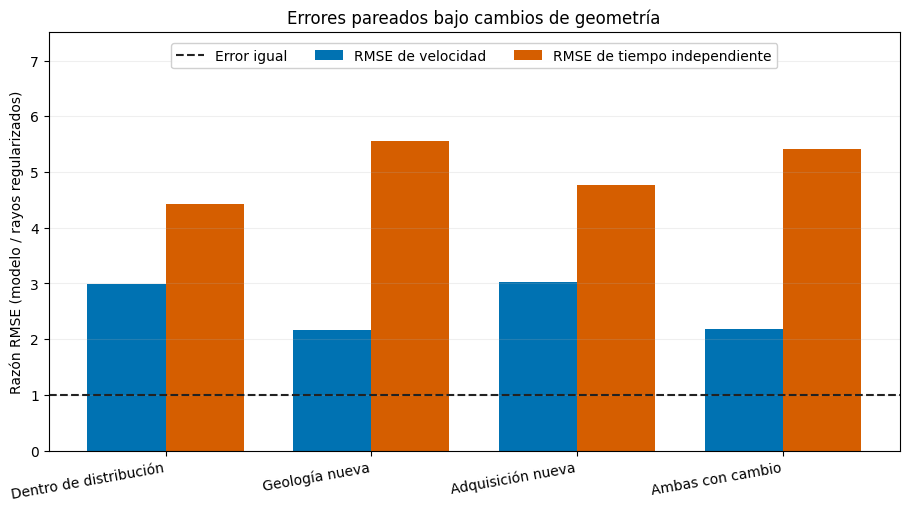

In [5]:
# Grafica razones de error agregadas en las cuatro cohortes retenidas.
labels = {"id_test": "Dentro de distribución", "family_only": "Geología nueva",
          "acquisition_only": "Adquisición nueva", "joint_ood": "Ambas con cambio"}
positions = np.arange(len(test_names))
velocity_ratio = [scores[name]["learned_to_classical_velocity_ratio"] for name in test_names]
time_ratio = [scores[name]["learned_to_classical_oracle_ratio"] for name in test_names]
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
ax.bar(positions - 0.19, velocity_ratio, width=0.38, color="#0072B2", label="RMSE de velocidad")
ax.bar(positions + 0.19, time_ratio, width=0.38, color="#D55E00", label="RMSE de tiempo independiente")
ax.axhline(1, color="#222222", linestyle="--", label="Error igual")
ax.set_xticks(positions, [labels[name] for name in test_names], rotation=10, ha="right")
ax.set_ylim(0, max(velocity_ratio + time_ratio) * 1.35)
ax.set_ylabel("Razón RMSE (modelo / rayos regularizados)")
ax.set_title("Errores pareados bajo cambios de geometría")
ax.legend(frameon=True, framealpha=0.92, ncols=3, loc="upper center", bbox_to_anchor=(0.5, 0.99))
ax.grid(axis="y", alpha=0.2)
plt.show()

El panel de cambio conjunto desagrega la población del agregado: cada punto es una realización pareada, no una geología independiente. Los límites punteados marcan errores equivalentes. Un punto abajo a la izquierda mejora ambas métricas; otros cuadrantes revelan compensaciones o regresiones.

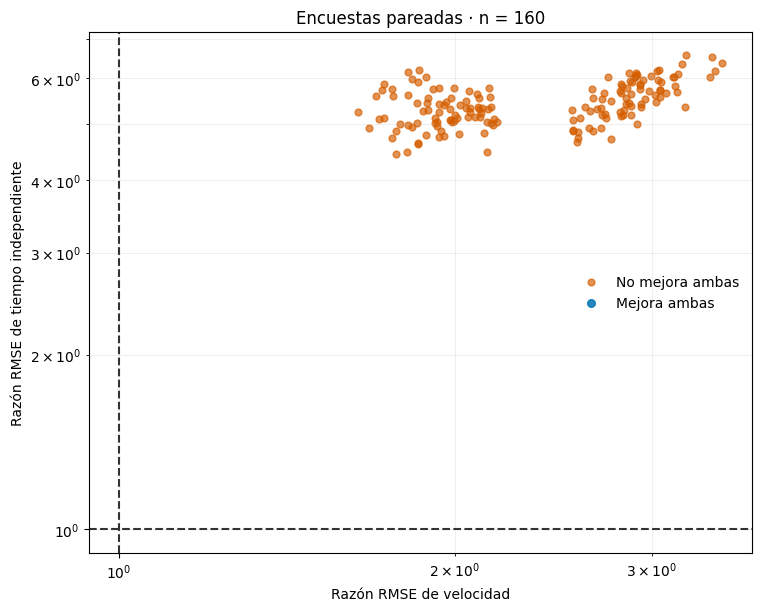

Mejora ambas: 0 de 160


In [6]:
# Cada punto compara ambos errores de una misma encuesta sintética.
joint_scores = scores["joint_ood"]["per_record"]
velocity_pairs = np.asarray([row["learned_velocity_rmse_m_s"] / row["classical_velocity_rmse_m_s"] for row in joint_scores])
time_pairs = np.asarray([row["learned_oracle_rmse_ms"] / row["classical_oracle_rmse_ms"] for row in joint_scores])
both_improved = (velocity_pairs < 1) & (time_pairs < 1)
fig, ax = plt.subplots(figsize=(7.5, 6), constrained_layout=True)
ax.scatter(velocity_pairs[~both_improved], time_pairs[~both_improved], s=24, alpha=0.68, color="#D55E00", label="No mejora ambas")
ax.scatter(velocity_pairs[both_improved], time_pairs[both_improved], s=30, alpha=0.85, color="#0072B2", label="Mejora ambas")
ax.axvline(1, color="#333333", linestyle="--")
ax.axhline(1, color="#333333", linestyle="--")
ax.set(xscale="log", yscale="log", xlabel="Razón RMSE de velocidad", ylabel="Razón RMSE de tiempo independiente", title="Encuestas pareadas · n = 160")
ax.legend(frameon=False)
ax.grid(which="both", alpha=0.18)
plt.show()
print("Mejora ambas:", int(both_improved.sum()), "de", len(joint_scores))

## Resultados

**Respuesta:** No. Las razones de RMSE de velocidad y tiempo independiente en cambio conjunto son 2,1875 y 5,4173; ambas superan 1,0. El modelo pierde frente a la inversión regularizada en las dos medidas declaradas. Las cohortes son sintéticas y no cuantifican precisión de campo.

## Resumen

El notebook deriva la característica residual, aplica la CNN guardada a encuestas retenidas regeneradas y la compara con una inversión de rayos regularizada, seleccionada con validación. La hipótesis no se sostiene: ambas razones agregadas superan uno. El resultado se limita al generador de rayos rectos de 16 × 16, su ruido y sus geometrías; no establece desempeño en campo ni en FWI de onda completa.

## Referencias

1. Göppel, S., Frikel, J. y Haltmeier, M. (2023). *Data-proximal null-space networks for inverse problems*. [arXiv](https://arxiv.org/abs/2309.06573), [DOI: 10.48550/arXiv.2309.06573](https://doi.org/10.48550/arXiv.2309.06573).
2. LANL, [repositorio del benchmark OpenFWI](https://github.com/lanl/OpenFWI); sus datos no se cargan.
3. Implementación reproducible: `data-pipeline/velocity_physics_refinement.py`, `data-pipeline/velocity_validation.py` y `models/experimental/m12-physics-cuda-20261004/`.